# D4D Senegal Descriptive Analysis

This notebook reads Set1, Set2, and Set3 and completes an exploratory analysis. 

In [2]:
from pathlib import Path
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PatchCollection
from matplotlib.patches import Polygon
plt.style.use('seaborn-v0_8-whitegrid')

def find_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / 'set1' / 'data').is_dir() and (candidate / 'set3' / 'indicators').is_dir():
            return candidate
    raise FileNotFoundError('Repository root was not found.')

ROOT = find_root()
SET1, SET2, SET3 = ROOT / 'set1', ROOT / 'set2' / 'arrondissment', ROOT / 'set3' / 'indicators'
print('Repository:', ROOT)

Repository: c:\Users\b1113715\Downloads\d4d_senegal


## 1. Load and validate the datasets

Set1 contains sparse district communication records. Set2 contains tower-level indicators and raw period files. Set3 contains arrondissement-level indicators.

In [3]:
def read_set1(path):
    frame = pd.read_csv(path, header=None)
    if frame.shape[1] == 4:
        frame.columns = ['period', 'source', 'target', 'value']
        frame['target_or_period'] = frame['target']
    elif frame.shape[1] == 3:
        frame.columns = ['source', 'target_or_period', 'value']
        frame['period'] = np.nan
        frame['target'] = frame['target_or_period']
    else:
        raise ValueError(f'Unexpected Set1 schema in {path}: {frame.shape[1]} columns')
    return frame

set1 = {path.name: read_set1(path) for path in sorted((SET1 / 'data').iterdir())}
set2_all = pd.read_csv(SET2 / 'data' / 'arrond')
set2_raw = {path.name: pd.read_csv(path, sep='\t') for path in sorted((SET2 / 'data').glob('arrond[0-9]*'))}
set3 = pd.read_csv(SET3 / 'data' / 'arrondissement.csv', sep='\t')
summary = pd.DataFrame({'file': list(set1), 'rows': [len(frame) for frame in set1.values()], 'columns': [frame.shape[1] for frame in set1.values()], 'unique_periods': [frame.period.nunique(dropna=True) for frame in set1.values()], 'unique_sources': [frame.source.nunique() for frame in set1.values()], 'unique_targets': [frame.target.nunique() for frame in set1.values()]})
display(summary)
print('Set2 combined:', set2_all.shape, '| Set2 raw period files:', len(set2_raw), '| Set3:', set3.shape)
display(set3.describe().T[['count', 'mean', 'min', 'max']].head(12))


## 2. Read supplied Senegal, district, tower, and arrondissement geometry

In [4]:
def read_xy(path, delimiter=',', skip_first=False):
    points = []
    with open(path, newline='') as handle:
        for line_number, row in enumerate(csv.reader(handle, delimiter=delimiter)):
            if skip_first and line_number == 0:
                continue
            if len(row) >= 3:
                points.append((float(row[1]), float(row[2])))
            elif len(row) >= 2:
                points.append((float(row[0]), float(row[1])))
    return np.asarray(points)

country = read_xy(SET1 / 'meta' / 'senegalshape')
district_polygons = [read_xy(SET1 / 'outlines' / f'lines{i}', skip_first=True) for i in range(123)]
district_centers = np.array([polygon.mean(axis=0) for polygon in district_polygons])
tower_polygons = [read_xy(SET2 / 'towers' / f'polygon{i}', delimiter='\t') for i in range(1, 1667) if (SET2 / 'towers' / f'polygon{i}').exists()]
arrondissement_polygons = [read_xy(SET3 / 'outlines' / f'lines{i}', skip_first=True) for i in range(123)]
print('Country points:', len(country), '| district centers:', len(district_centers), '| tower polygons:', len(tower_polygons), '| arrondissement polygons:', len(arrondissement_polygons))

Country points: 2238 | district centers: 123 | tower polygons: 1666 | arrondissement polygons: 123


## 3. Location and Set1 communication-network maps

The network plots show the strongest 1% of district-to-district links. This percentile threshold is a plotting choice and can be changed.

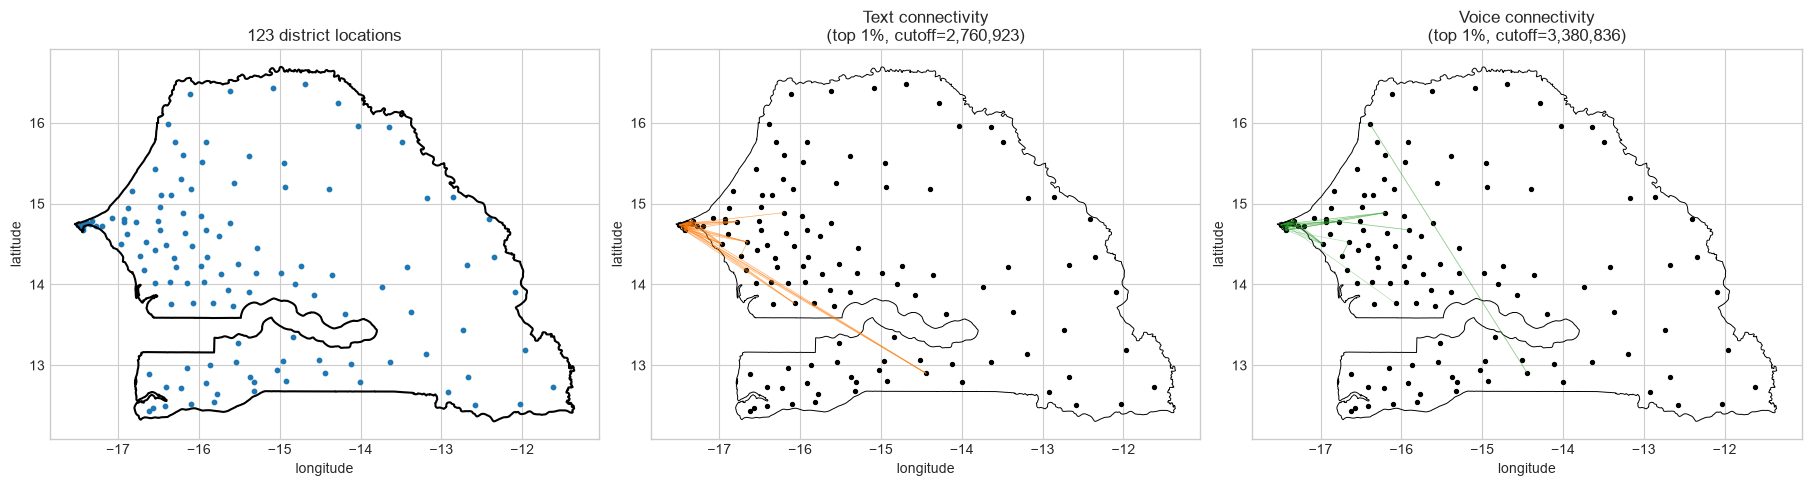

In [5]:
def connectivity_edges(frame, percentile=99):
    positive = frame[frame.value > 0]
    cutoff = np.percentile(positive.value, percentile)
    selected = positive[positive.value >= cutoff]
    segments = [[district_centers[int(row.source) - 1], district_centers[int(row.target_or_period) - 1]] for row in selected.itertuples() if 1 <= row.source <= 123 and 1 <= row.target_or_period <= 123]
    return np.asarray(segments), cutoff

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
axes[0].plot(country[:, 0], country[:, 1], color='black')
axes[0].scatter(district_centers[:, 0], district_centers[:, 1], s=10)
axes[0].set_title('123 district locations')
for axis, filename, title, color in zip(axes[1:], ['text_total_district', 'voice_total_district_count'], ['Text connectivity', 'Voice connectivity'], ['tab:orange', 'tab:green']):
    segments, cutoff = connectivity_edges(set1[filename])
    axis.plot(country[:, 0], country[:, 1], color='black', linewidth=0.7)
    if len(segments):
        axis.add_collection(LineCollection(segments, colors=color, linewidths=0.5, alpha=0.35))
    axis.scatter(district_centers[:, 0], district_centers[:, 1], s=8, color='black')
    axis.set_title(f'{title}\n(top 1%, cutoff={cutoff:,.0f})')
for axis in axes:
    axis.set_aspect('equal')
    axis.set_xlabel('longitude')
    axis.set_ylabel('latitude')
plt.show()

## 4. Set1 spatial-temporal summaries

In [6]:
periods = [('hour', 'text_hour_district', 'voice_hour_district_count'), ('weekday', 'text_weekday_district', 'voice_weekday_district_count'), ('week', 'text_week_district', 'voice_week_district_count'), ('month', 'text_month_district', 'voice_month_district_count')]
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for axis, (label, text_name, voice_name) in zip(axes.flat, periods):
    text_profile = set1[text_name].groupby('period').value.sum()
    voice_profile = set1[voice_name].groupby('period').value.sum()
    axis.plot(text_profile.index, text_profile.values, marker='o', label='text')
    axis.plot(voice_profile.index, voice_profile.values, marker='o', label='voice')
    axis.set_title(f'Set1 activity by {label}')
    axis.set_xlabel(label)
    axis.set_ylabel('aggregated value')
    axis.legend()
plt.show()
top = set1['text_total_district'].groupby('source').value.sum().sort_values().tail(15)
top.plot.barh(figsize=(10, 6), title='Top districts by total text activity')
plt.xlabel('activity value')
plt.show()


## 5. Set2 tower-level indicator maps and rankings

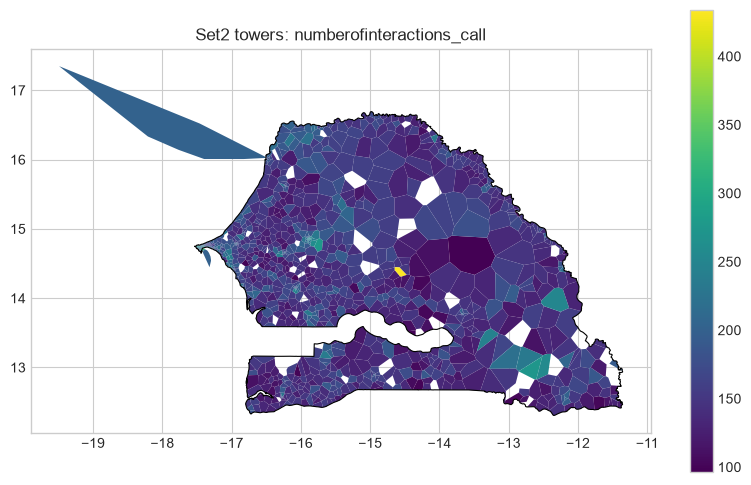

,arrid,numberofinteractions_call,numberofcontacts_call,percentathome_all,radiusofgyration_all
1344,1345.0,434.000000,59.000000,0.520000,11534.799805
305,306.0,400.272727,111.704545,0.443182,11059.018033
282,283.0,341.919206,82.616901,0.309895,8097.873554
0,1.0,330.218832,74.176006,0.311791,7808.993602
270,271.0,325.971803,81.375037,0.297784,8043.580565
288,289.0,321.399963,74.734600,0.311108,7960.149931
264,265.0,310.903040,76.155750,0.306485,7890.876894
196,197.0,309.893362,84.228163,0.348668,8300.253342
210,211.0,306.400783,77.715370,0.322295,7914.527201
256,257.0,303.869502,80.591302,0.324980,8059.156127


In [7]:
def polygon_map(polygons, values, title, cmap='viridis'):
    fig, axis = plt.subplots(figsize=(10, 8))
    patches, colors = [], []
    for polygon, value in zip(polygons, values):
        if len(polygon) >= 3 and np.isfinite(value):
            patches.append(Polygon(polygon, closed=True))
            colors.append(value)
    collection = PatchCollection(patches, array=np.asarray(colors), cmap=cmap, edgecolor='none')
    axis.add_collection(collection)
    axis.plot(country[:, 0], country[:, 1], color='black', linewidth=0.8)
    axis.autoscale()
    axis.set_aspect('equal')
    axis.set_title(title)
    fig.colorbar(collection, ax=axis, shrink=0.75)
    plt.show()

indicator = 'numberofinteractions_call'
n = min(len(tower_polygons), len(set2_all))
polygon_map(tower_polygons[:n], set2_all[indicator].to_numpy()[:n], f'Set2 towers: {indicator}')
ranking = set2_all[['arrid', 'numberofinteractions_call', 'numberofcontacts_call', 'percentathome_all', 'radiusofgyration_all']]
display(ranking.sort_values('numberofinteractions_call', ascending=False).head(15))

## 6. Set3 arrondissement maps, rankings, and correlations

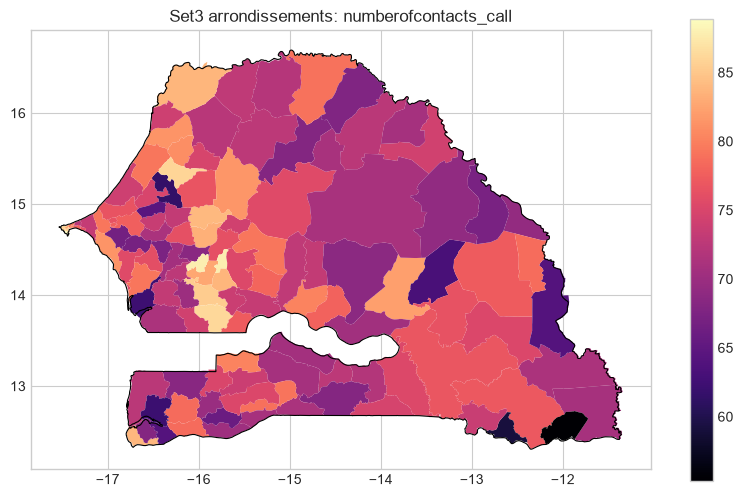

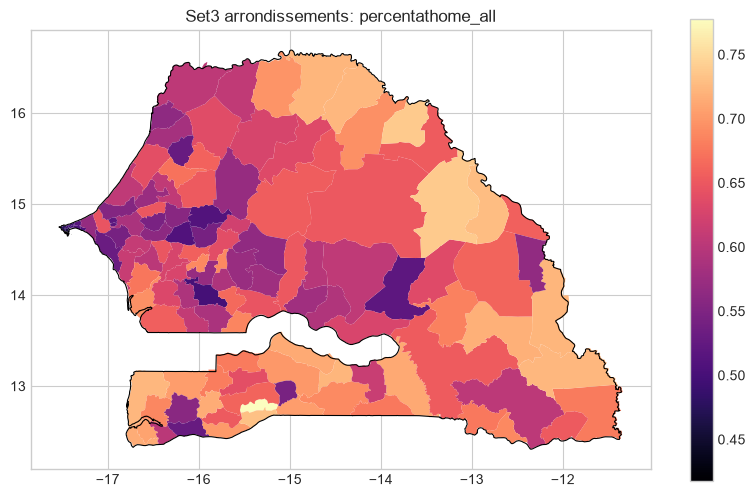

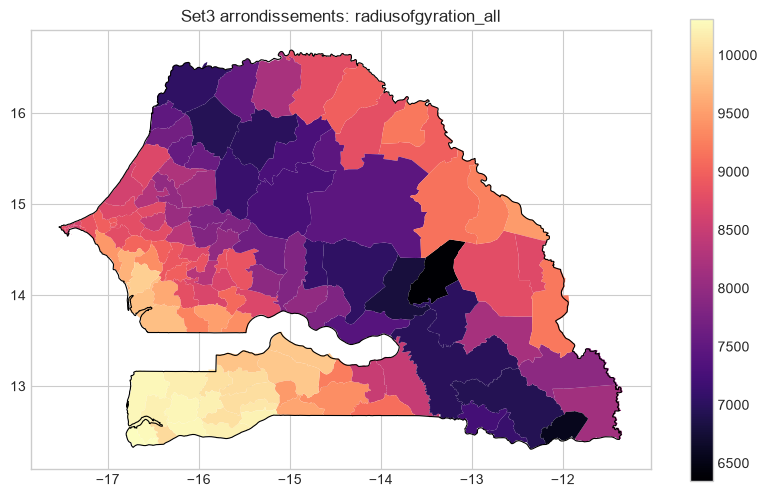

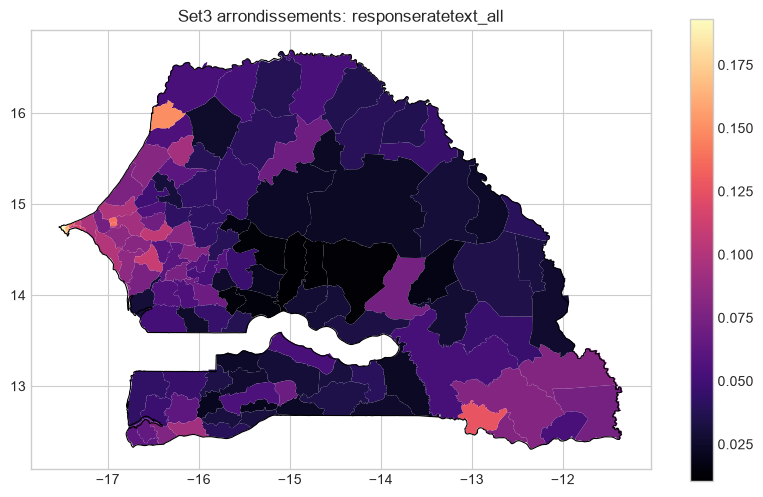

,arrid,numberofcontacts_call,numberofcontacts_text,numberofinteractions_call,numberofinteractions_text,percentathome_all,percentnocturnal_call,radiusofgyration_all,responseratetext_all
3,4,88.913202,33.357155,379.444125,296.739313,0.417879,0.345489,8577.609654,0.173533
1,2,85.938147,34.298775,377.354054,352.695978,0.473291,0.367547,8780.557361,0.193275
2,3,85.941948,31.300983,374.785156,311.013881,0.458450,0.366400,8677.556676,0.165542
92,93,83.853894,20.920448,368.940712,91.963158,0.716074,0.353797,10312.649161,0.062299
24,25,84.033404,14.139724,360.462625,78.120087,0.509792,0.313455,7761.260460,0.042326
11,12,81.309852,24.310188,358.840110,176.914587,0.531063,0.367908,9460.801212,0.101143
0,1,82.687038,30.664237,355.754995,305.433564,0.493007,0.384361,8684.083142,0.157630
55,56,86.236551,16.930767,353.457184,92.793915,0.587215,0.353560,9510.577132,0.045363
53,54,85.255580,19.230352,352.047739,112.670398,0.498962,0.356907,8677.599617,0.069255
10,11,79.223695,18.161030,349.888499,114.172780,0.647059,0.351451,8974.814038,0.072111


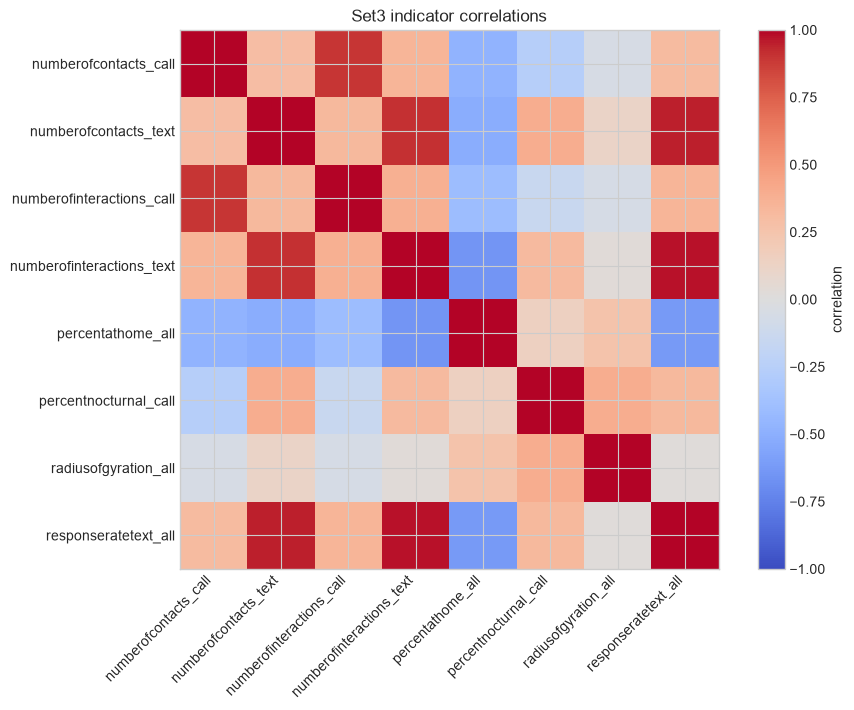

In [8]:
for indicator in ['numberofcontacts_call', 'percentathome_all', 'radiusofgyration_all', 'responseratetext_all']:
    polygon_map(arrondissement_polygons, set3[indicator].to_numpy(), f'Set3 arrondissements: {indicator}', cmap='magma')
selected = ['numberofcontacts_call', 'numberofcontacts_text', 'numberofinteractions_call', 'numberofinteractions_text', 'percentathome_all', 'percentnocturnal_call', 'radiusofgyration_all', 'responseratetext_all']
display(set3[['arrid', *selected]].sort_values('numberofinteractions_call', ascending=False).head(15))
corr = set3[selected].corr()
fig, axis = plt.subplots(figsize=(10, 7))
image = axis.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
axis.set_xticks(range(len(selected)), selected, rotation=45, ha='right')
axis.set_yticks(range(len(selected)), selected)
fig.colorbar(image, ax=axis, label='correlation')
axis.set_title('Set3 indicator correlations')
plt.show()

## Interpretation and caveats

- Set1 values are preserved as supplied; units should not be inferred without additional metadata.
- Set2 raw period files are tab-separated, while the combined `data/arrond` file is comma-separated.
- Polygon means are representative district locations, not individual user GPS positions.
- Indicator units and observation windows are not fully documented in the supplied files.
- Change the Set1 percentile threshold to control network density.
- If `seaborn` is unavailable, install it in the notebook kernel or replace the correlation heatmap with Matplotlib.

## 7. All towers and temporal-grain check

This section plots all 1,666 Set2 tower polygons and compares the 25 raw Set2 files. The repository has no timestamps or file-to-date lookup, so these files are confirmed as 25 repeated snapshots/windows, but not as hourly, daily, weekly, or monthly data.


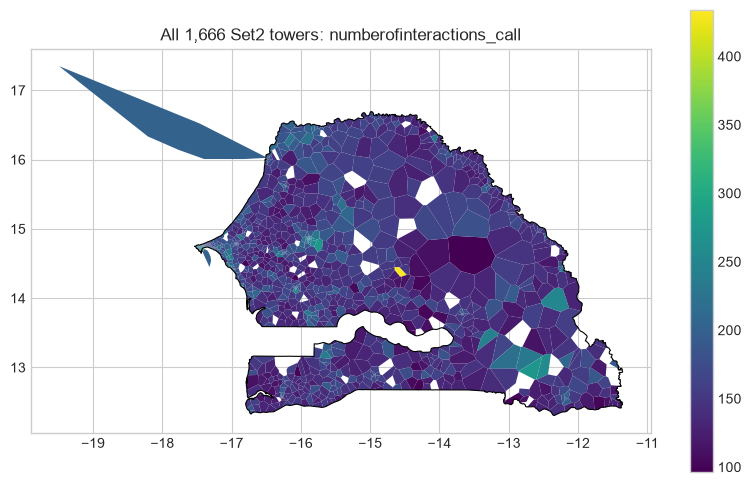

,mean,snapshot_number
raw_file,,
arrond01,171.203326,1
arrond02,165.296438,2
arrond03,167.183465,3
arrond04,167.008696,4
arrond05,172.069260,5
arrond06,165.760170,6
arrond07,173.146274,7
arrond08,175.724076,8
arrond09,180.280576,9


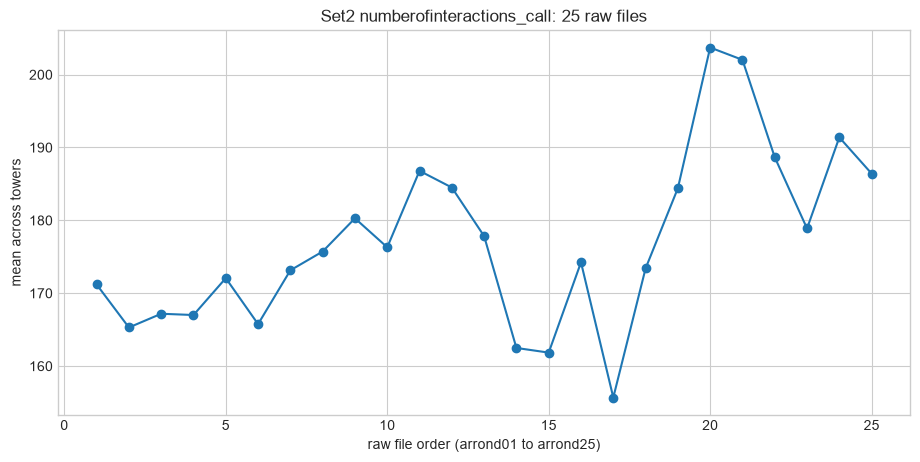

Temporal-grain confirmation:
- Set1: explicit hourly, weekday, weekly, and monthly files; total files have no time index.
- Set2: arrond01-arrond25 are 25 repeated indicator tables per tower. No timestamps or cadence are present.
- Set3: one 123-arrondissement indicator table with no time index; its observation window is not documented here.


In [9]:
# Plot every available tower polygon, colored by a selected Set2 indicator.
tower_indicator = 'numberofinteractions_call'
values = set2_all[tower_indicator].to_numpy()
polygon_map(tower_polygons, values[:len(tower_polygons)], f'All {len(tower_polygons):,} Set2 towers: {tower_indicator}', cmap='viridis')

# Compare the 25 raw files. The x-axis is file order, not a calendar date.
raw_order = sorted(set2_raw)
raw_means = pd.DataFrame({name: frame[tower_indicator].mean() for name, frame in ((name, set2_raw[name]) for name in raw_order)}, index=['mean']).T
raw_means.index.name = 'raw_file'
raw_means['snapshot_number'] = np.arange(1, len(raw_means) + 1)
display(raw_means)
ax = raw_means.plot(x='snapshot_number', y='mean', marker='o', figsize=(11, 5), legend=False, title=f'Set2 {tower_indicator}: 25 raw files')
ax.set_xlabel('raw file order (arrond01 to arrond25)')
ax.set_ylabel('mean across towers')
plt.show()

print('Temporal-grain confirmation:')
print('- Set1: explicit hourly, weekday, weekly, and monthly files; total files have no time index.')
print('- Set2: arrond01-arrond25 are 25 repeated indicator tables per tower. No timestamps or cadence are present.')
print('- Set3: one 123-arrondissement indicator table with no time index; its observation window is not documented here.')


## Hadoop pipeline interpretation

The Hadoop jobs establish the Set1 schemas. `aggregate_texts.pig` loads `(timestamp, outgoing_tower, incoming_tower, nTexts)` and `aggregate_voice.pig` loads `(timestamp, outgoing_tower, incoming_tower, nCalls, totalDuration)`. They aggregate by total, month, ISO week, ISO weekday, and hour. Spark then replaces tower IDs with district IDs and sums duplicate district pairs.

Therefore, Set1 temporal files are four-column records `(time_bucket, source_district, target_district, value)`. Total files are three-column records `(source_district, target_district, value)`. The first hour bucket is 0; months, weekdays, and weeks use calendar values generated by Pig. The files are aggregates over the full source observation period, not individual hourly event records.


## 8. Set2 processing pipeline and coverage caveats

Set2 is built around 1,666 mobile-phone tower areas. The supplied MATLAB script creates Voronoi polygons from tower coordinates and clips them to Senegal. The 25 files `arrond01` through `arrond25` contain tower-level behavioral indicators. `average.py` loops over those 25 files and calculates one mean value per tower, writing `data/arrond.csv`.

The available code does not contain timestamps or a date-to-file lookup. Therefore, the 25 files are repeated measurement windows, but they cannot be identified as hourly, daily, weekly, or monthly. The indicators include active days, call/text contacts and interactions, call duration, mobility radius, at-home percentage, nocturnal activity, and text response rate.

The current query scripts have a delimiter difference: `queryStatistics.py` expects tab-separated combined data, while `queryStatisticsCombined.py` correctly reads the comma-separated combined file. Four invalid tower polygons are excluded by the original map code. Some raw windows contain fewer than 1,666 towers, so missing values must be checked before interpreting the averaged map.


In [10]:
# Set2 coverage by raw measurement window.
coverage = pd.DataFrame([
    {
        'raw_file': name,
        'rows': len(frame),
        'unique_towers': frame['arrid'].nunique(),
        'missing_cells': int(frame.isna().sum().sum()),
        'min_arrid': int(frame['arrid'].min()),
        'max_arrid': int(frame['arrid'].max()),
    }
    for name, frame in sorted(set2_raw.items())
])
display(coverage)
print('Combined Set2 shape:', set2_all.shape)
print('Combined missing cells:', int(set2_all.isna().sum().sum()))
print('Combined unique tower IDs:', set2_all['arrid'].nunique())


,raw_file,rows,unique_towers,missing_cells,min_arrid,max_arrid
0,arrond01,1495,1495,0,1,1666
1,arrond02,1495,1495,0,1,1666
2,arrond03,1505,1505,0,1,1666
3,arrond04,1506,1506,0,1,1666
4,arrond05,1510,1510,0,1,1666
5,arrond06,1514,1514,0,1,1666
6,arrond07,1514,1514,0,1,1666
7,arrond08,1523,1523,0,1,1666
8,arrond09,1521,1521,0,1,1666
9,arrond10,1528,1528,0,1,1666


Combined Set2 shape: (1666, 34)
Combined missing cells: 1958
Combined unique tower IDs: 1609
